In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import scipy.stats
import mdtraj as md
from typing import Dict, Tuple
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)

def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

outpath='./HDX_stats_plots/'


Total unique proteins: 8


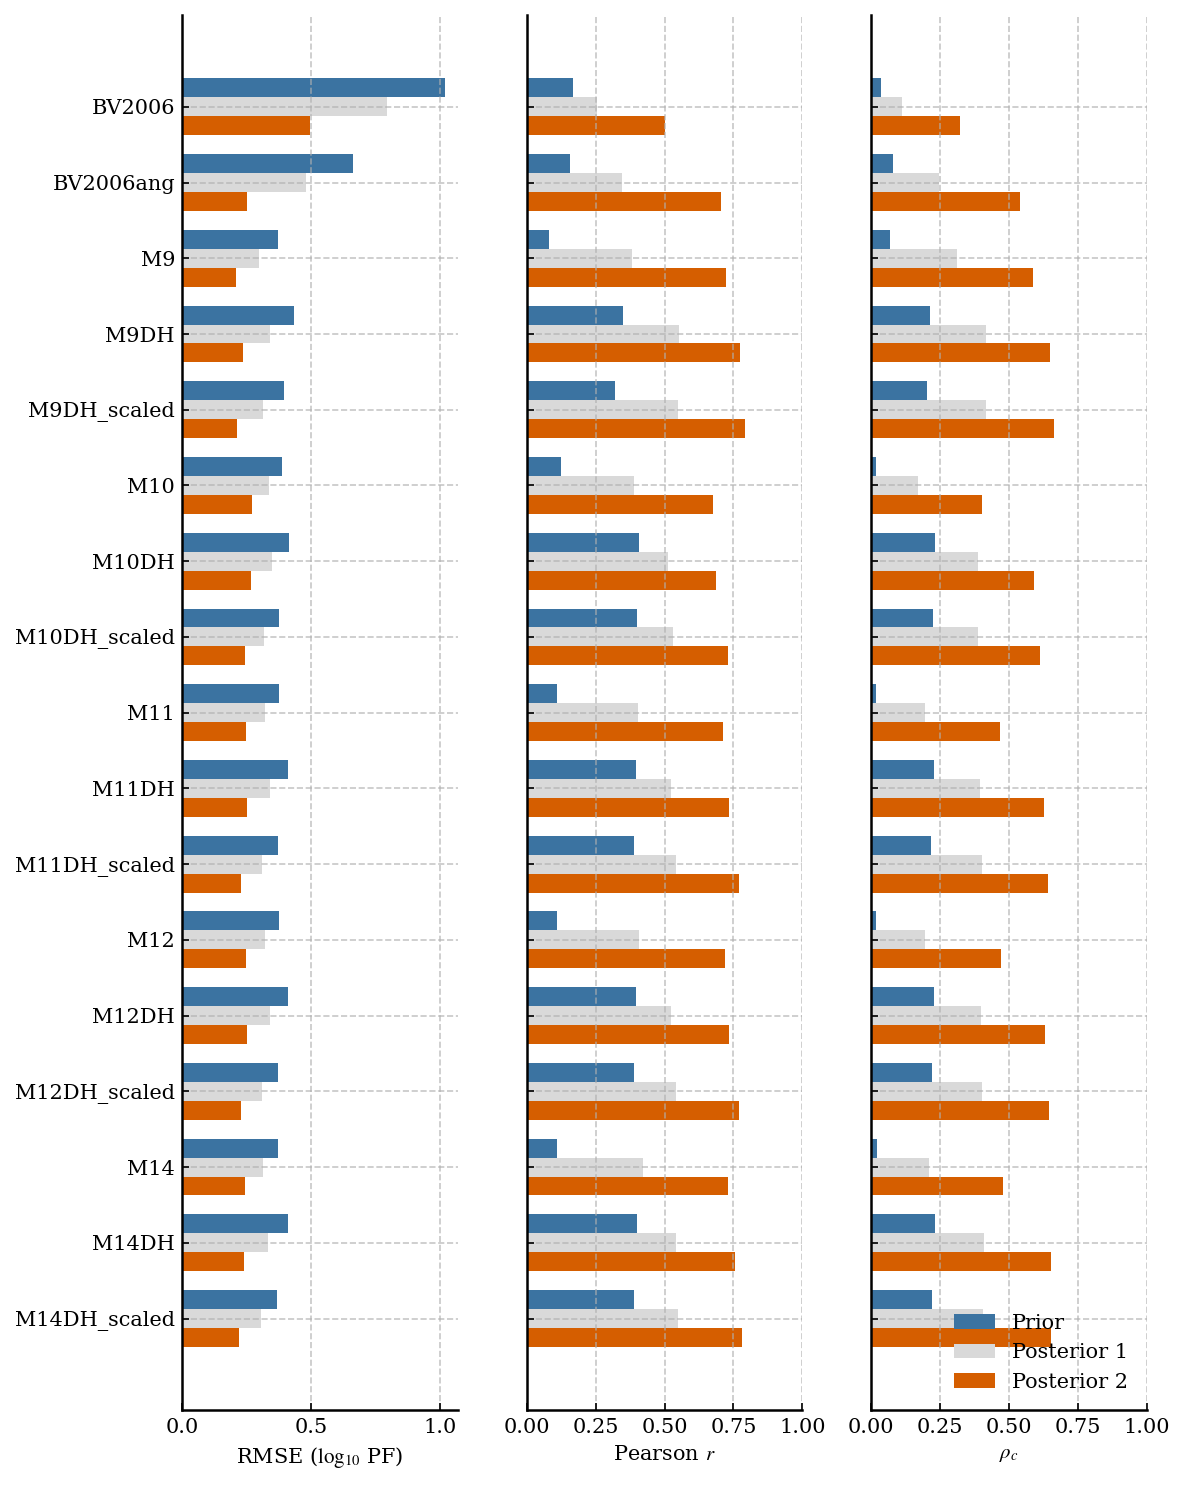

In [2]:
# --------------------------------------------------
# Models and labels
# --------------------------------------------------
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

labels = [model[3:] for model in models]

proteins_list = [
    ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail'],
    ['aSyn', 'drkN'],
    ['ACTR', 'aSyn', 'd131d', 'drkN', 'NTail'],
    ['ACTR', 'aSyn', 'd131d', 'drkN'],
    ['ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail'],
    ['ACTR', 'aSyn', 'BecN', 'ChiZ', 'drkN']
]

# --------------------------------------------------
# Flatten and sort unique proteins
# --------------------------------------------------
flat = [protein for sublist in proteins_list for protein in sublist]
proteins = sorted(set(flat))

print("Total unique proteins:", len(proteins))

# --------------------------------------------------
# Storage for mean values
# --------------------------------------------------
rmse_prior_mean = []
rmse_post1_mean = []
rmse_post2_mean = []

r_prior_mean = []
r_post1_mean = []
r_post2_mean = []

ccc_prior_mean = []
ccc_post1_mean = []
ccc_post2_mean = []

# --------------------------------------------------
# Loop through models
# --------------------------------------------------
for model in models:

    rmse_prior_vals = []
    rmse_post1_vals = []
    rmse_post2_vals = []

    r_prior_vals = []
    r_post1_vals = []
    r_post2_vals = []

    ccc_prior_vals = []
    ccc_post1_vals = []
    ccc_post2_vals = []

    for protein in proteins:

        # Load PFs
        expPF = np.asarray(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['PF'], dtype=float)
        PFprior = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/prior_lnPF.txt"))
        if 'BV' in model:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF_elbow.txt"))
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF.txt"))
        else:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF_elbow.txt"))  
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt"))

        # Convert to log10 PF
        exp_log = np.log10(expPF)
        prior_log = np.log10(PFprior)
        post1_log = np.log10(PFpost1)
        post2_log = np.log10(PFpost2)

        # Calculate statistics
        rmse_prior_vals.append(RMSE(exp_log, prior_log))
        rmse_post1_vals.append(RMSE(exp_log, post1_log))
        rmse_post2_vals.append(RMSE(exp_log, post2_log))

        r_prior_vals.append(scipy.stats.pearsonr(exp_log, prior_log)[0])
        r_post1_vals.append(scipy.stats.pearsonr(exp_log, post1_log)[0])
        r_post2_vals.append(scipy.stats.pearsonr(exp_log, post2_log)[0])

        ccc_prior_vals.append(calc_ccc(exp_log, prior_log))
        ccc_post1_vals.append(calc_ccc(exp_log, post1_log))
        ccc_post2_vals.append(calc_ccc(exp_log, post2_log))

    # Store means across proteins
    rmse_prior_mean.append(np.mean(rmse_prior_vals))
    rmse_post1_mean.append(np.mean(rmse_post1_vals))
    rmse_post2_mean.append(np.mean(rmse_post2_vals))

    r_prior_mean.append(np.mean(r_prior_vals))
    r_post1_mean.append(np.mean(r_post1_vals))
    r_post2_mean.append(np.mean(r_post2_vals))

    ccc_prior_mean.append(np.mean(ccc_prior_vals))
    ccc_post1_mean.append(np.mean(ccc_post1_vals))
    ccc_post2_mean.append(np.mean(ccc_post2_vals))

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"  # prior
COLOR1 = "#D55E00"  # posterior 2
COLOR2 = "#D9D9D9"  # posterior 1

colors = {'Prior': COLOR3, 'Posterior 1': COLOR2, 'Posterior 2': COLOR1}

# --------------------------------------------------
# Organise plotting results
# --------------------------------------------------
results = {
    'RMSE': {'Prior': rmse_prior_mean, 'Posterior 1': rmse_post1_mean, 'Posterior 2': rmse_post2_mean},
    'Pearson r': {'Prior': r_prior_mean, 'Posterior 1': r_post1_mean, 'Posterior 2': r_post2_mean},
    'CCC': {'Prior': ccc_prior_mean, 'Posterior 1': ccc_post1_mean, 'Posterior 2': ccc_post2_mean}
}

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(8, 10), sharey=True)

stages = ['Prior', 'Posterior 1', 'Posterior 2']
stat_names = ['RMSE', 'Pearson r', 'CCC']
xlabels = [r'RMSE ($\log_{10}$ PF)', r'Pearson $r$', r'$\mathit{\rho_c}$']

n_models = len(models)
n_stages = len(stages)
bar_height = 0.25
y = np.arange(n_models)

for ax, stat_name, xlabel in zip(axes, stat_names, xlabels):

    for i, stage_name in enumerate(stages):
        offset = (i - (n_stages - 1) / 2) * bar_height
        ax.barh(y + offset, results[stat_name][stage_name], height=bar_height, label=stage_name, color=colors[stage_name])

    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)
    if stat_name == 'Pearson r' or stat_name == 'CCC':
        ax.set_xlim(0, 1)

axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()

axes[-1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(outpath+'HDX_reweighting_models_summary_barplot_all.pdf', dpi=300, bbox_inches='tight')
plt.show()

Total unique proteins: 8


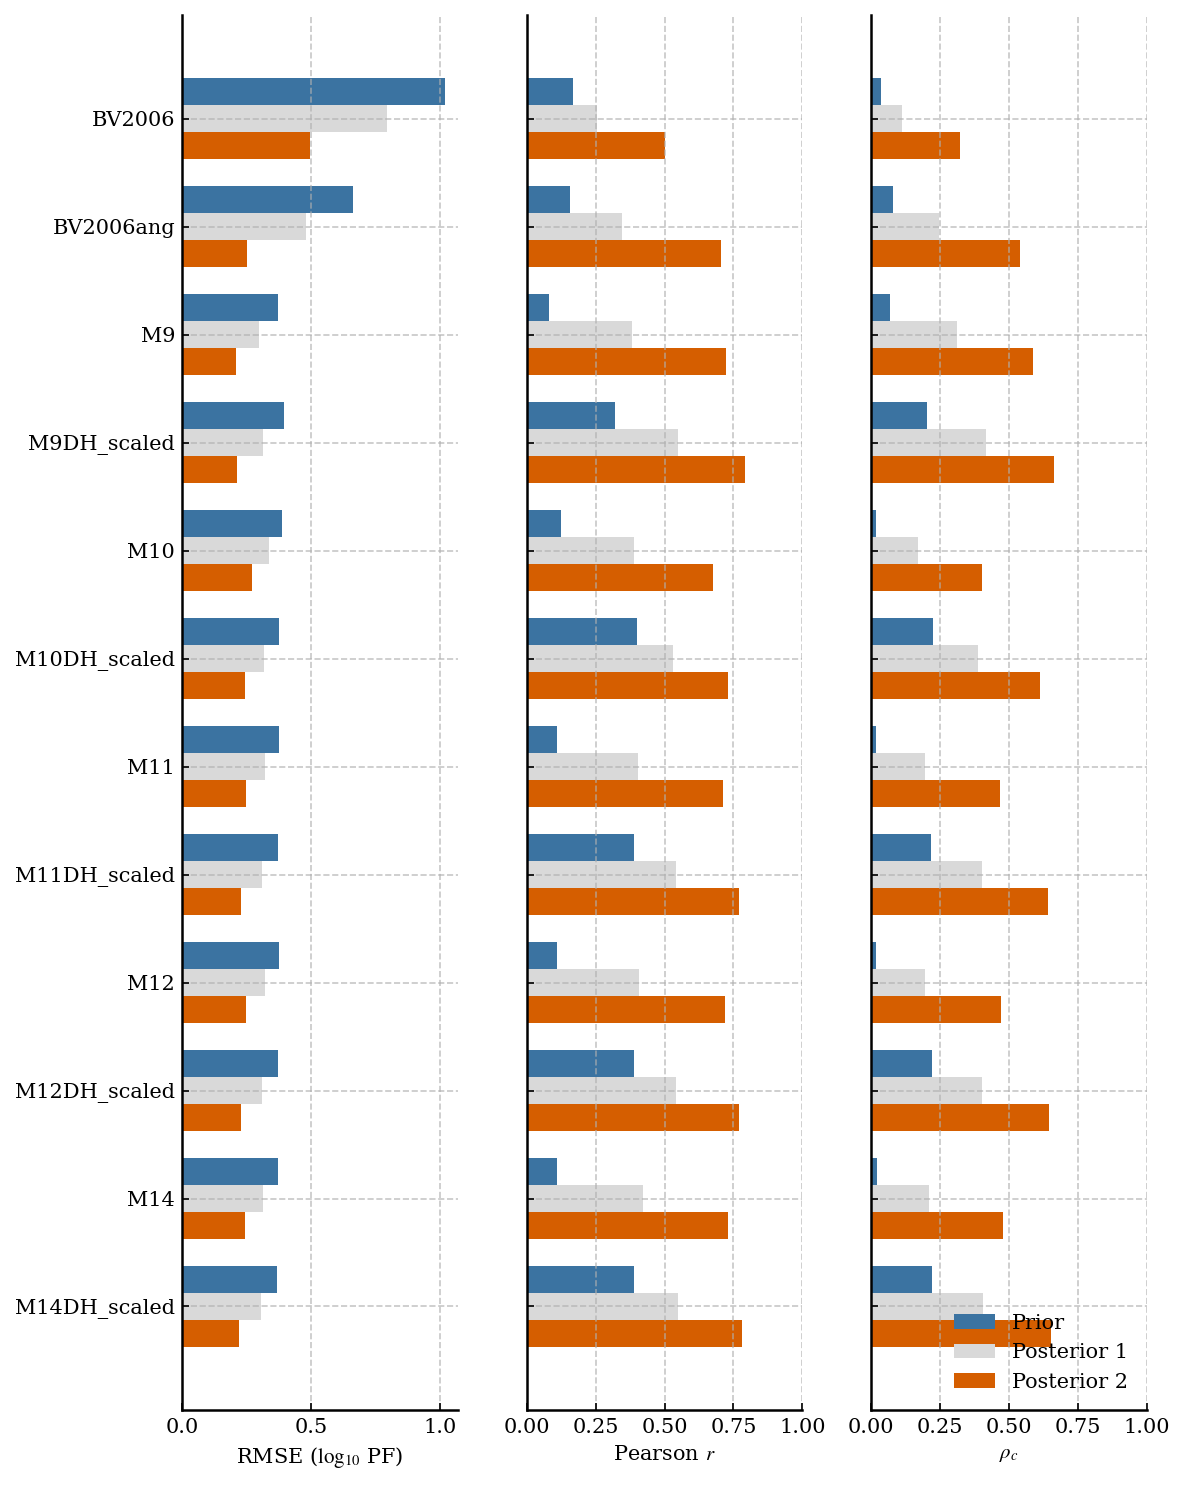

In [17]:
# --------------------------------------------------
# Models and labels
# --------------------------------------------------
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH_scaled', 'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled', 'rewM14', 'rewM14DH_scaled']

labels = [model[3:] for model in models]

proteins_list = [
    ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail'],
    ['aSyn', 'drkN'],
    ['ACTR', 'aSyn', 'd131d', 'drkN', 'NTail'],
    ['ACTR', 'aSyn', 'd131d', 'drkN'],
    ['ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail'],
    ['ACTR', 'aSyn', 'BecN', 'ChiZ', 'drkN']
]

# --------------------------------------------------
# Flatten and sort unique proteins
# --------------------------------------------------
flat = [protein for sublist in proteins_list for protein in sublist]
proteins = sorted(set(flat))

print("Total unique proteins:", len(proteins))

# --------------------------------------------------
# Storage for mean values
# --------------------------------------------------
rmse_prior_mean = []
rmse_post1_mean = []
rmse_post2_mean = []

r_prior_mean = []
r_post1_mean = []
r_post2_mean = []

ccc_prior_mean = []
ccc_post1_mean = []
ccc_post2_mean = []

# --------------------------------------------------
# Loop through models
# --------------------------------------------------
for model in models:

    rmse_prior_vals = []
    rmse_post1_vals = []
    rmse_post2_vals = []

    r_prior_vals = []
    r_post1_vals = []
    r_post2_vals = []

    ccc_prior_vals = []
    ccc_post1_vals = []
    ccc_post2_vals = []

    for protein in proteins:

        # Load PFs
        expPF = np.asarray(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['PF'], dtype=float)
        PFprior = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/prior_lnPF.txt"))
        if 'BV' in model:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF_elbow.txt"))
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF.txt"))
        else:
            PFpost1 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF_elbow.txt"))  
            PFpost2 = np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt"))

        # Convert to log10 PF
        exp_log = np.log10(expPF)
        prior_log = np.log10(PFprior)
        post1_log = np.log10(PFpost1)
        post2_log = np.log10(PFpost2)

        # Calculate statistics
        rmse_prior_vals.append(RMSE(exp_log, prior_log))
        rmse_post1_vals.append(RMSE(exp_log, post1_log))
        rmse_post2_vals.append(RMSE(exp_log, post2_log))

        r_prior_vals.append(scipy.stats.pearsonr(exp_log, prior_log)[0])
        r_post1_vals.append(scipy.stats.pearsonr(exp_log, post1_log)[0])
        r_post2_vals.append(scipy.stats.pearsonr(exp_log, post2_log)[0])

        ccc_prior_vals.append(calc_ccc(exp_log, prior_log))
        ccc_post1_vals.append(calc_ccc(exp_log, post1_log))
        ccc_post2_vals.append(calc_ccc(exp_log, post2_log))

    # Store means across proteins
    rmse_prior_mean.append(np.mean(rmse_prior_vals))
    rmse_post1_mean.append(np.mean(rmse_post1_vals))
    rmse_post2_mean.append(np.mean(rmse_post2_vals))

    r_prior_mean.append(np.mean(r_prior_vals))
    r_post1_mean.append(np.mean(r_post1_vals))
    r_post2_mean.append(np.mean(r_post2_vals))

    ccc_prior_mean.append(np.mean(ccc_prior_vals))
    ccc_post1_mean.append(np.mean(ccc_post1_vals))
    ccc_post2_mean.append(np.mean(ccc_post2_vals))

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"  # prior
COLOR1 = "#D55E00"  # posterior 2
COLOR2 = "#D9D9D9"  # posterior 1

colors = {'Prior': COLOR3, 'Posterior 1': COLOR2, 'Posterior 2': COLOR1}

# --------------------------------------------------
# Organise plotting results
# --------------------------------------------------
results = {
    'RMSE': {'Prior': rmse_prior_mean, 'Posterior 1': rmse_post1_mean, 'Posterior 2': rmse_post2_mean},
    'Pearson r': {'Prior': r_prior_mean, 'Posterior 1': r_post1_mean, 'Posterior 2': r_post2_mean},
    'CCC': {'Prior': ccc_prior_mean, 'Posterior 1': ccc_post1_mean, 'Posterior 2': ccc_post2_mean}
}

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(8, 10), sharey=True)

stages = ['Prior', 'Posterior 1', 'Posterior 2']
stat_names = ['RMSE', 'Pearson r', 'CCC']
xlabels = [r'RMSE ($\log_{10}$ PF)', r'Pearson $r$', r'$\mathit{\rho_c}$']

n_models = len(models)
n_stages = len(stages)
bar_height = 0.25
y = np.arange(n_models)

for ax, stat_name, xlabel in zip(axes, stat_names, xlabels):

    for i, stage_name in enumerate(stages):
        offset = (i - (n_stages - 1) / 2) * bar_height
        ax.barh(y + offset, results[stat_name][stage_name], height=bar_height, label=stage_name, color=colors[stage_name])

    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)
    if stat_name == 'Pearson r' or stat_name == 'CCC':
        ax.set_xlim(0, 1)

axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()

axes[-1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(outpath+'HDX_reweighting_models_summary_barplot.pdf', dpi=300, bbox_inches='tight')
plt.show()

Total unique proteins: 8


/tmp/ipykernel_1781796/1110732243.py:41: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  r_prior_vals.append(float(stats['rpearson prior']))
/tmp/ipykernel_1781796/1110732243.py:42: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  r_post_vals.append(float(stats['rpearson post']))
/tmp/ipykernel_1781796/1110732243.py:44: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rmse_prior_vals.append(float(stats['rmse prior']))
/tmp/ipykernel_1781796/1110732243.py:45: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rmse_post_vals.append(float(stats['rmse post']))
/tmp/ipykernel_1781796/1110732243.py:41: FutureWarning

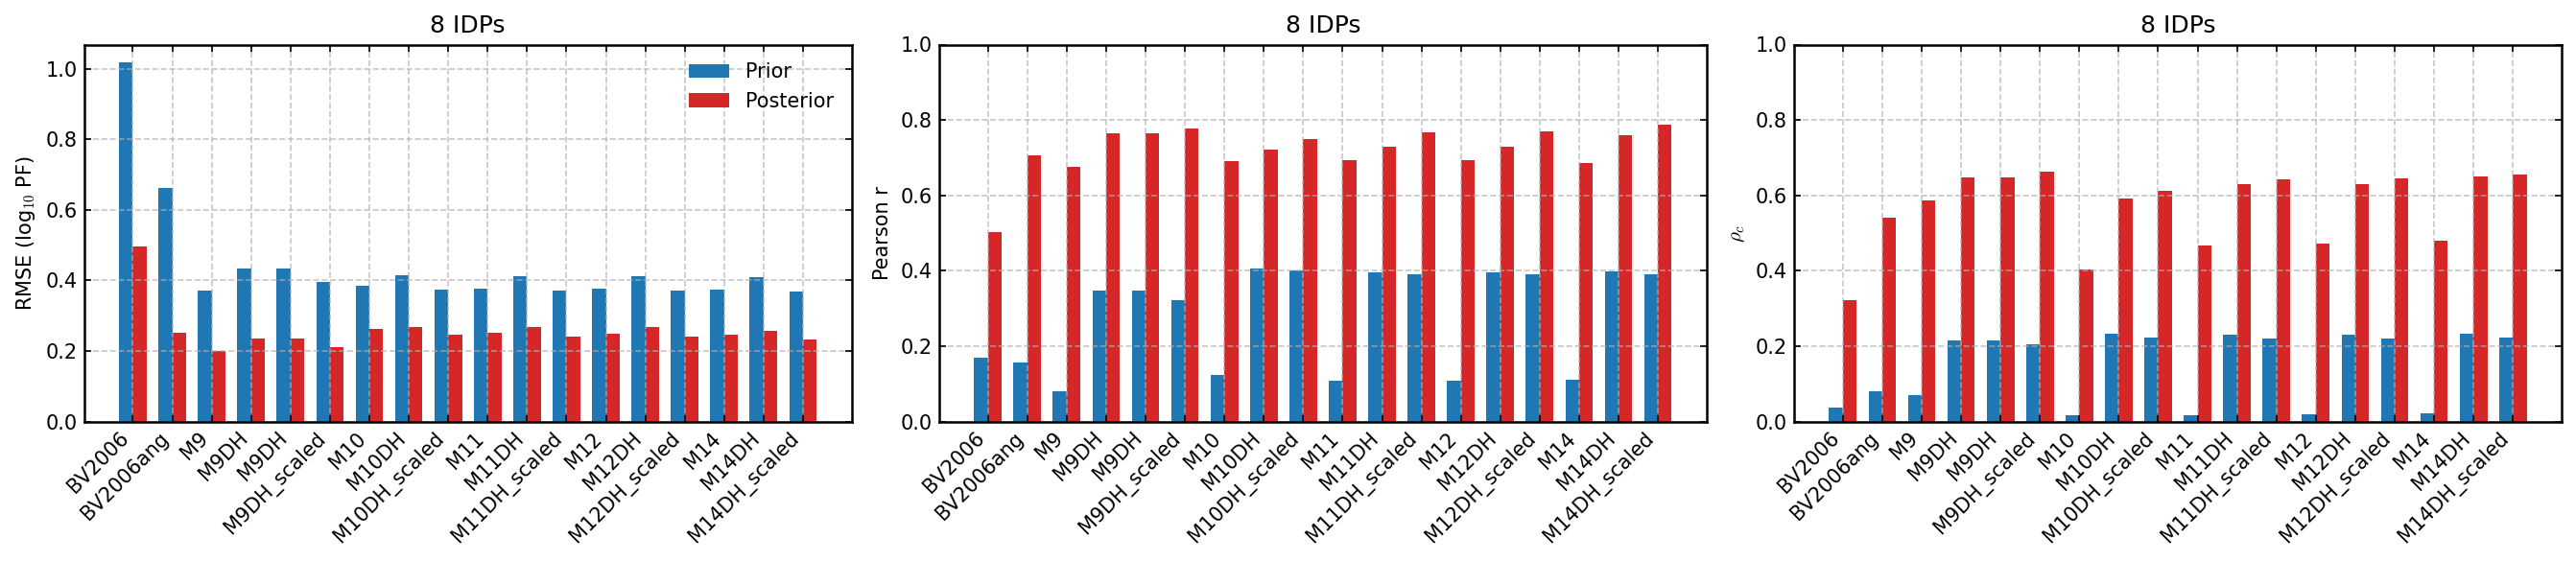

In [ ]:
## old version not loading the correct stats_df file (should be log_lamba prefix for M based models)

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']
labels = [model[3:] for model in models]

proteins_list = [
    ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail'],
    ['aSyn', 'drkN'],
    ['ACTR', 'aSyn', 'd131d', 'drkN', 'NTail'],
    ['ACTR', 'aSyn', 'd131d', 'drkN'],
    ['ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail'],
    ['ACTR', 'aSyn', 'BecN', 'ChiZ', 'drkN']
]

# ---- Flatten and sort unique proteins ----
flat = [p for sub in proteins_list for p in sub]
proteins = sorted(set(flat))
print("Total unique proteins:", len(proteins))

# ---- storage for means ----
rmse_prior_mean  = []
rmse_post_mean   = []
r_prior_mean     = []
r_post_mean      = []
ccc_prior_mean = []
ccc_post_mean = []

# ---- loop through models ----
for model in models:

    rmse_prior_vals = []
    rmse_post_vals  = []
    r_prior_vals    = []
    r_post_vals     = []
    ccc_prior_vals = []
    ccc_post_vals = []

    for protein in proteins:
        stats = pd.read_csv(f"../../MD_DATA/{protein}/{model}/stats_df.csv")

        r_prior_vals.append(float(stats['rpearson prior']))
        r_post_vals.append(float(stats['rpearson post']))

        rmse_prior_vals.append(float(stats['rmse prior']))
        rmse_post_vals.append(float(stats['rmse post']))

        prior_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/prior_lnPF.txt")))
        if model in ('rewBV2006', 'rewBV2006ang'):
            post_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/rew_lnPF.txt")))
        else:
            post_PF = np.log10(np.exp(np.loadtxt(f"../../MD_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt")))
        
        exp_PF = np.log10(pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")['PF'])

        ccc_prior_vals.append(calc_ccc(prior_PF,exp_PF))
        ccc_post_vals.append(calc_ccc(post_PF,exp_PF))


    # store means
    rmse_prior_mean.append(np.mean(rmse_prior_vals))
    rmse_post_mean.append(np.mean(rmse_post_vals))
    r_prior_mean.append(np.mean(r_prior_vals))
    r_post_mean.append(np.mean(r_post_vals))
    ccc_prior_mean.append(np.mean(ccc_prior_vals))
    ccc_post_mean.append(np.mean(ccc_post_vals))

    

# ---- Plot: Three Panels (RMSE, Pearson r, CCC) ----

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
bar_width = 0.35
x = np.arange(len(models))

# ===== LEFT PANEL: RMSE =====
ax = axes[0]

ax.bar(x - bar_width/2, rmse_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, rmse_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} IDPs")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("RMSE (log$_{10}$ PF)")
ax.legend()

# ===== MIDDLE PANEL: Pearson r =====
ax = axes[1]

ax.bar(x - bar_width/2, r_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, r_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} IDPs")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("Pearson r")
ax.set_ylim(0, 1)

# ===== RIGHT PANEL: CCC =====
ax = axes[2]

ax.bar(x - bar_width/2, ccc_prior_mean, bar_width, label="Prior", color="tab:blue")
ax.bar(x + bar_width/2, ccc_post_mean,  bar_width, label="Posterior", color="tab:red")
ax.set_title(f"{len(proteins)} IDPs")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel(r"$\rho_c$")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig("models_HDXstats_summary.png", dpi=200, bbox_inches="tight")